<a href="https://colab.research.google.com/github/Bvsrkrishna/Data-Analyst-and-Engineering/blob/main/CLV%20end%20to%20end%20Pipeline%20analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# End-to-End Customer Lifetime Value Analytics



In [ ]:
#@title Setup (run first) { display-mode: "form" }
import sys, os
from pathlib import Path
IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = False  #@param {type:"boolean"}
if IN_COLAB and USE_DRIVE:
    from google.colab import drive; drive.mount("/content/drive"); BASE = Path("/content/drive/MyDrive/clv_project")   # files survive between sessions
elif IN_COLAB:
    BASE = Path("/content/clv_project")                                                                              # lost when runtime resets
else:
    BASE = Path.cwd() / "clv_project"
BASE.mkdir(parents=True, exist_ok=True); os.chdir(BASE)
print("Working folder:", BASE)

Working folder: /content/clv_project


---
# Part 1: Step 1 - Generate the synthetic CLV dataset

In [ ]:
import numpy as np, pandas as pd
from pathlib import Path


RAW = BASE / "data" / "raw"; RAW.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(42)
N_CUST, START, END = 4000, pd.Timestamp("2024-01-01"), pd.Timestamp("2025-12-31")
COUNTRIES = ["India", "USA", "UK", "Germany", "Canada", "Australia"]
CHANNELS = ["Organic", "Paid Search", "Social", "Email", "Referral"]
CATEGORIES = ["Electronics", "Home", "Fashion", "Beauty", "Sports", "Books"]

In [ ]:
RAW

PosixPath('/content/clv_project/data/raw')

### products

In [ ]:
# ---- products
products = pd.DataFrame({
    "product_id": np.arange(1, 61),
    "category": rng.choice(CATEGORIES, 60),
    "unit_price": np.round(rng.lognormal(3.4, 0.7, 60).clip(5, 400), 2)})
products["product_name"] = "Product " + products.product_id.astype(str)

In [ ]:
products

,product_id,category,unit_price,product_name
0,1,Electronics,134.18,Product 1
1,2,Sports,22.54,Product 2
2,3,Beauty,20.94,Product 3
3,4,Fashion,16.95,Product 4
4,5,Fashion,46.12,Product 5
5,6,Books,66.04,Product 6
6,7,Electronics,27.67,Product 7
7,8,Sports,16.64,Product 8
8,9,Home,16.82,Product 9
9,10,Electronics,47.25,Product 10


### customers

In [ ]:
# ---- customers
customers = pd.DataFrame({
    "customer_id": np.arange(1, N_CUST + 1),
    "signup_date": START + pd.to_timedelta(rng.integers(0, 600, N_CUST), unit="D"),
    "country": rng.choice(COUNTRIES, N_CUST, p=[.3, .25, .15, .1, .1, .1]),
    "acquisition_channel": rng.choice(CHANNELS, N_CUST, p=[.3, .25, .2, .15, .1]),
    "age": rng.integers(18, 70, N_CUST),
    "gender": rng.choice(["F", "M", "Other"], N_CUST, p=[.48, .48, .04])})

In [ ]:
customers

,customer_id,signup_date,country,acquisition_channel,age,gender
0,1,2024-10-24,UK,Social,27,F
1,2,2024-09-24,India,Social,25,F
2,3,2024-04-09,Australia,Referral,46,M
3,4,2024-08-16,USA,Paid Search,50,F
4,5,2024-05-23,India,Organic,24,F
...,...,...,...,...,...,...
3995,3996,2024-10-06,India,Email,49,F
3996,3997,2025-01-26,USA,Organic,24,M
3997,3998,2024-08-04,Germany,Paid Search,44,F
3998,3999,2024-03-01,India,Social,59,F


### transactions (BG/NBD-like: each customer buys at a personal rate, then churns)

In [ ]:
# ---- transactions (BG/NBD-like: each customer buys at a personal rate, then churns)
rows, oid = [], 100000
rate = rng.gamma(1.5, 0.35, N_CUST)           # orders / month
life = rng.exponential(14, N_CUST) * 30       # active lifetime in days
aov_mult = rng.lognormal(0, 0.35, N_CUST)
for i, c in customers.iterrows():
    t, cutoff = c.signup_date, c.signup_date + pd.Timedelta(days=life[i])
    while t <= END and t <= cutoff:
        oid += 1
        n_items = rng.integers(1, 5)
        for p in rng.choice(products.index, n_items, replace=False):
            rows.append((oid, c.customer_id, products.product_id[p], t.normalize(),
                         int(rng.integers(1, 4)),
                         round(products.unit_price[p] * aov_mult[i], 2),
                         rng.choice([0, 0, 0.05, 0.10]),
                         c.country, rng.choice(["Web", "App", "Store"], p=[.5, .35, .15])))
        t += pd.Timedelta(days=float(rng.exponential(30 / rate[i])) + 0.5)
tx = pd.DataFrame(rows, columns=["order_id", "customer_id", "product_id", "order_date",
                                 "quantity", "unit_price", "discount", "country", "order_channel"])

In [ ]:
tx

,order_id,customer_id,product_id,order_date,quantity,unit_price,discount,country,order_channel
0,100001,1,54,2024-10-24,2,19.80,0.00,UK,Web
1,100001,1,49,2024-10-24,3,40.07,0.00,UK,App
2,100001,1,52,2024-10-24,1,16.27,0.00,UK,Web
3,100002,1,9,2025-03-17,3,14.52,0.00,UK,Web
4,100002,1,19,2025-03-17,2,41.59,0.00,UK,App
...,...,...,...,...,...,...,...,...,...
55483,122260,4000,9,2025-12-24,1,14.31,0.00,India,Web
55484,122260,4000,53,2025-12-24,3,19.77,0.10,India,Web
55485,122261,4000,7,2025-12-25,3,23.54,0.05,India,Web
55486,122261,4000,29,2025-12-25,2,13.90,0.00,India,Store


### inject dirt (ETL must fix these)

In [ ]:
# ---- inject dirt (ETL must fix these)
tx.loc[tx.sample(frac=.02, random_state=1).index, "quantity"] *= -1          # returns
tx.loc[tx.sample(frac=.01, random_state=2).index, "country"] = None          # missing
tx.loc[tx.sample(frac=.005, random_state=3).index, "customer_id"] = np.nan   # guest checkout
tx = pd.concat([tx, tx.sample(frac=.01, random_state=4)])                    # duplicates
tx["order_date"] = tx["order_date"].dt.strftime("%Y-%m-%d")
customers["signup_date"] = customers["signup_date"].dt.strftime("%Y-%m-%d")

customers.to_csv(RAW / "customers.csv", index=False)
products.to_csv(RAW / "products.csv", index=False)
tx.sample(frac=1, random_state=9).to_csv(RAW / "transactions.csv", index=False)
print(f"customers={len(customers):,} products={len(products)} transaction_lines={len(tx):,}")

customers=4,000 products=60 transaction_lines=56,043


---
# Part 2: Step 2 - ETL pipeline (Extract, Transform, Validate, Load)

In [ ]:
import os, sys, logging, time
import numpy as np, pandas as pd
from pathlib import Path


RAW, OUT = BASE / "data" / "raw", BASE / "data" / "processed"
OUT.mkdir(parents=True, exist_ok=True)
logging.basicConfig(force=True, level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s")
log = logging.getLogger("etl")
audit = []                                   # collected for the etl_audit table

def record(step, rows_in, rows_out, status="OK"):
    audit.append({"step": step, "rows_in": rows_in, "rows_out": rows_out, "status": status})
    log.info("%-22s in=%-8s out=%-8s %s", step, rows_in, rows_out, status)

### EXTRACT

In [ ]:
# ---------------------------------------------------------------- EXTRACT
def extract():
    tx = pd.read_csv(RAW / "transactions.csv")
    cu = pd.read_csv(RAW / "customers.csv")
    pr = pd.read_csv(RAW / "products.csv")
    record("extract", len(tx), len(tx))
    return tx, cu, pr

### TRANSFORM

In [ ]:
# ---------------------------------------------------------------- TRANSFORM
def transform(tx, cu, pr):
    n0 = len(tx)
    tx = tx.drop_duplicates().copy();                              record("drop_duplicates", n0, len(tx))
    n = len(tx); tx = tx.dropna(subset=["customer_id"]).copy();    record("drop_guest_rows", n, len(tx))
    tx["customer_id"] = tx.customer_id.astype(int)
    tx["order_date"] = pd.to_datetime(tx.order_date, errors="coerce")
    n = len(tx); tx = tx.dropna(subset=["order_date"]);            record("valid_dates", n, len(tx))

    returns = tx[tx.quantity <= 0]; returns.to_csv(OUT / "returns.csv", index=False)
    n = len(tx); tx = tx[tx.quantity > 0].copy();                  record("remove_returns", n, len(tx))

    n = len(tx)
    tx = tx[(tx.unit_price > 0) & tx.discount.between(0, 1)]
    tx = tx[tx.customer_id.isin(cu.customer_id) & tx.product_id.isin(pr.product_id)].copy()
    record("referential_checks", n, len(tx))

    # impute missing country from the customer master
    cmap = cu.set_index("customer_id").country
    tx["country"] = tx.country.fillna(tx.customer_id.map(cmap)).fillna("Unknown").str.strip().str.title()
    tx["line_revenue"] = (tx.quantity * tx.unit_price * (1 - tx.discount)).round(2)

    cu = cu.copy(); cu["signup_date"] = pd.to_datetime(cu.signup_date)
    cu["country"] = cu.country.fillna("Unknown"); cu["gender"] = cu.gender.fillna("Other")
    return tx.reset_index(drop=True), cu, pr

### VALIDATE

In [ ]:
# ---------------------------------------------------------------- VALIDATE
def validate(tx):
    checks = {"no_null_keys": tx[["order_id", "customer_id", "product_id"]].notna().all().all(),
              "positive_revenue": (tx.line_revenue > 0).all(),
              "no_dupes": not tx.duplicated().any(),
              "dates_in_range": tx.order_date.between("2024-01-01", "2025-12-31").all()}
    for k, v in checks.items(): log.info("check %-18s %s", k, "PASS" if v else "FAIL")
    if not all(checks.values()): raise ValueError(f"Data quality failed: {checks}")
    record("validate", len(tx), len(tx))

### FEATURES (RFM snapshot)

In [ ]:
# ---------------------------------------------------------------- FEATURES (RFM snapshot)
def build_rfm(tx):
    o = tx.groupby(["order_id", "customer_id", "order_date"], as_index=False).line_revenue.sum()
    snap = o.order_date.max() + pd.Timedelta(days=1)
    rfm = o.groupby("customer_id").agg(
        recency_days=("order_date", lambda s: (snap - s.max()).days),
        frequency=("order_id", "nunique"), monetary=("line_revenue", "sum"),
        first_order=("order_date", "min"), last_order=("order_date", "max")).reset_index()
    rfm["monetary"] = rfm.monetary.round(2); rfm["aov"] = (rfm.monetary / rfm.frequency).round(2)
    for col, asc in [("recency_days", False), ("frequency", True), ("monetary", True)]:
        rfm[col[0] + "_score"] = pd.qcut(rfm[col].rank(method="first", ascending=asc), 5, labels=False) + 1
    r, f = rfm.r_score, rfm.f_score
    rfm["rfm_segment"] = np.select(
        [(r >= 4) & (f >= 4), (r >= 3) & (f >= 3), (r >= 4) & (f <= 2), (r <= 2) & (f >= 3), (r <= 2) & (f <= 2)],
        ["Champions", "Loyal", "New / Promising", "At Risk", "Lost"], "Needs Attention")
    return rfm, o

### LOAD

In [ ]:
# ---------------------------------------------------------------- LOAD
def load(tx, cu, pr, rfm, orders):
    tx.to_csv(OUT / "transactions_clean.csv", index=False)
    cu.to_csv(OUT / "customers_clean.csv", index=False)
    pr.to_csv(OUT / "products_clean.csv", index=False)
    orders.to_csv(OUT / "orders.csv", index=False)
    rfm.to_csv(OUT / "rfm.csv", index=False)
    record("load_csv", len(tx), len(tx))
    url = os.getenv("MYSQL_URL")
    if not url:
        log.warning("MYSQL_URL not set -> skipped MySQL load (CSV outputs written)"); return
    from sqlalchemy import create_engine, text      # pip install sqlalchemy pymysql
    eng = create_engine(url)
    with eng.begin() as c:
        c.execute(text("SET FOREIGN_KEY_CHECKS=0"))
        for t in ["fact_transactions", "dim_customer", "dim_product"]: c.execute(text(f"TRUNCATE TABLE {t}"))
        c.execute(text("SET FOREIGN_KEY_CHECKS=1"))
    cols = ["order_id", "customer_id", "product_id", "order_date", "quantity", "unit_price",
            "discount", "line_revenue", "country", "order_channel"]
    cu.to_sql("dim_customer", eng, if_exists="append", index=False)
    pr.to_sql("dim_product", eng, if_exists="append", index=False)
    tx[cols].to_sql("fact_transactions", eng, if_exists="append", index=False, chunksize=5000)
    pd.DataFrame(audit).to_sql("etl_audit", eng, if_exists="append", index=False)
    log.info("Loaded into MySQL")

def main():
    t0 = time.time()
    tx, cu, pr = extract()
    tx, cu, pr = transform(tx, cu, pr)
    validate(tx)
    rfm, orders = build_rfm(tx)
    load(tx, cu, pr, rfm, orders)
    log.info("ETL done in %.1fs | rows=%s customers=%s", time.time() - t0, f"{len(tx):,}", f"{len(rfm):,}")

main()

2026-11-07 15:06:34,245 | INFO | extract                in=56043    out=56043    OK
2026-11-07 15:06:34,267 | INFO | drop_duplicates        in=56043    out=55488    OK
2026-11-07 15:06:34,273 | INFO | drop_guest_rows        in=55488    out=55211    OK
2026-11-07 15:06:34,285 | INFO | valid_dates            in=55211    out=55211    OK
2026-11-07 15:06:34,295 | INFO | remove_returns         in=55211    out=54106    OK
2026-11-07 15:06:34,300 | INFO | referential_checks     in=54106    out=54106    OK
2026-11-07 15:06:34,345 | INFO | check no_null_keys       PASS
2026-11-07 15:06:34,346 | INFO | check positive_revenue   PASS
2026-11-07 15:06:34,347 | INFO | check no_dupes           PASS
2026-11-07 15:06:34,348 | INFO | check dates_in_range     PASS
2026-11-07 15:06:34,349 | INFO | validate               in=54106    out=54106    OK
2026-11-07 15:06:34,935 | INFO | load_csv               in=54106    out=54106    OK
2026-11-07 15:06:34,936 | WARNING | MYSQL_URL not set -> skipped MySQL load 

---
# Part 3: EDA - Basics

In [ ]:
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
RAW = BASE / "data" / "raw"; FIG = BASE / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160, "display.max_columns", 20)
def h(t): print(f"\n{'='*8} {t} {'='*8}")
RAW

PosixPath('/content/clv_project/data/raw')

### 1. NumPy essentials

In [ ]:
h("1. NumPy essentials")
a = np.array([[1, 2, 3], [4, 5, 6]])
print(a.shape, a.dtype, a.ndim, a.size, np.zeros(3), np.ones((2, 2)), np.arange(0, 10, 3), np.linspace(0, 1, 5))
print(a.mean(), a.sum(axis=0), a.sum(axis=1), a[:, 1], a[a > 2], a.reshape(3, 2).T.shape, a * 2, a @ a.T)
print(np.where(a > 3, "hi", "lo").tolist(), np.random.default_rng(1).normal(0, 1, 3).round(2), np.nan_to_num(np.array([1, np.nan])))
print("percentile:", np.percentile([1, 2, 3, 4, 100], [25, 50, 75]), "std:", np.std([2, 4, 4, 4, 5, 5, 7, 9]))


======== 1. NumPy essentials ========
(2, 3) int64 2 6 [0. 0. 0.] [[1. 1.]
 [1. 1.]] [0 3 6 9] [0.   0.25 0.5  0.75 1.  ]
3.5 [5 7 9] [ 6 15] [2 5] [3 4 5 6] (2, 3) [[ 2  4  6]
 [ 8 10 12]] [[14 32]
 [32 77]]
[['lo', 'lo', 'lo'], ['hi', 'hi', 'hi']] [0.35 0.82 0.33] [1. 0.]
percentile: [2. 3. 4.] std: 2.0


### 2. Load data

In [ ]:
h("2. Load data")
tx = pd.read_csv(RAW / "transactions.csv")
cu = pd.read_csv(RAW / "customers.csv", parse_dates=["signup_date"])
pr = pd.read_csv(RAW / "products.csv")
print("loaded:", tx.shape, cu.shape, pr.shape)       # read_excel / read_json / read_sql work the same way


======== 2. Load data ========
loaded: (56043, 9) (4000, 6) (60, 4)


### 3. First look

In [ ]:
h("3. First look")
print(tx.head(3)); print(tx.tail(2)); print(tx.sample(3, random_state=1))
print(tx.shape, tx.columns.tolist()); tx.info()
print(tx.describe().round(2)); print(tx.describe(include="object").T if tx.select_dtypes("object").shape[1] else tx.describe(include="all").T.head(3))
print(tx.nunique()); print(tx.country.value_counts(dropna=False)); print(tx.order_channel.value_counts(normalize=True).round(3))
print("memory MB:", round(tx.memory_usage(deep=True).sum() / 1e6, 2))


======== 3. First look ========
   order_id  customer_id  product_id  order_date  quantity  unit_price  discount    country order_channel
0    113577       2446.0          17  2025-09-30         3       62.10      0.10     Canada           App
1    105695       1060.0          54  2024-11-28         1       15.88      0.00         UK           Web
2    107606       1421.0           9  2025-10-16         3       13.40      0.05  Australia           App
       order_id  customer_id  product_id  order_date  quantity  unit_price  discount  country order_channel
56041    114553       2619.0          31  2025-10-26         2        6.04       0.0  Germany         Store
56042    108373          NaN          58  2024-09-30         1       34.80       0.0    India           App
       order_id  customer_id  product_id  order_date  quantity  unit_price  discount country order_channel
32023    101415        230.0          54  2024-03-20         2       12.84      0.00   India           Web
28208

### 4. Selecting & filtering

In [ ]:
h("4. Selecting & filtering")
print(tx["country"].head(2).tolist(), tx[["order_id", "unit_price"]].head(2).values.tolist())
print(tx.loc[0:2, ["order_id", "quantity"]]); print(tx.iloc[0:2, 0:3])
big = tx[(tx.unit_price > 100) & (tx.quantity >= 2)]; print("big lines:", len(big))
print(len(tx[tx.country.isin(["India", "USA"])]), len(tx[~tx.order_channel.eq("Web")]), len(tx.query("discount > 0.05 and quantity == 3")))
print(len(tx[tx.country.isna()]), len(tx[tx.country.notna()]), len(tx[tx.unit_price.between(10, 20)]))


======== 4. Selecting & filtering ========
['Canada', 'UK'] [[113577.0, 62.1], [105695.0, 15.88]]
   order_id  quantity
0    113577         3
1    105695         1
2    107606         3
   order_id  customer_id  product_id
0    113577       2446.0          17
1    105695       1060.0          54
big lines: 1011
31234 27807 4613
565 55478 12456


### 5. Sort, rename, drop, index

In [ ]:
h("5. Sort, rename, drop, index")
print(tx.sort_values(["unit_price", "order_id"], ascending=[False, True]).head(3)[["order_id", "unit_price"]])
t2 = tx.rename(columns={"unit_price": "price"}).drop(columns=["order_channel"])
print(t2.columns.tolist()); print(tx.nlargest(2, "unit_price")[["unit_price"]], tx.set_index("order_id").loc[100001].shape)


======== 5. Sort, rename, drop, index ========
       order_id  unit_price
28974    102436      362.82
55460    100156      325.62
24591    117597      313.15
['order_id', 'customer_id', 'product_id', 'order_date', 'quantity', 'price', 'discount', 'country']
       unit_price
28974      362.82
55460      325.62 (3, 8)


### 6. Data types & dates

In [ ]:
h("6. Data types & dates")
tx["order_date"] = pd.to_datetime(tx.order_date); tx["customer_id"] = tx.customer_id.astype("Int64")
tx["country"] = tx.country.astype("category"); tx["quantity"] = pd.to_numeric(tx.quantity, downcast="integer")
tx["year"], tx["month"], tx["dow"] = tx.order_date.dt.year, tx.order_date.dt.month, tx.order_date.dt.day_name()
print(tx.dtypes.to_dict()); print(tx.order_date.min(), tx.order_date.max(), (tx.order_date.max() - tx.order_date.min()).days)


======== 6. Data types & dates ========
{'order_id': dtype('int64'), 'customer_id': Int64Dtype(), 'product_id': dtype('int64'), 'order_date': dtype('<M8[ns]'), 'quantity': dtype('int8'), 'unit_price': dtype('float64'), 'discount': dtype('float64'), 'country': CategoricalDtype(categories=['Australia', 'Canada', 'Germany', 'India', 'UK', 'USA'], ordered=False, categories_dtype=object), 'order_channel': dtype('O'), 'year': dtype('int32'), 'month': dtype('int32'), 'dow': dtype('O')}
2024-01-01 00:00:00 2025-12-30 00:00:00 729


### 7. Missing values

In [ ]:
h("7. Missing values")
print(tx.isna().sum()[lambda s: s > 0].to_dict(), f"{tx.isna().mean().max():.2%} max null rate")
t3 = tx.copy()
t3["country"] = t3.country.cat.add_categories("Unknown").fillna("Unknown")
print(t3.country.isna().sum(), len(tx.dropna(subset=["customer_id"])), len(tx.dropna()))
print(pd.Series([1, np.nan, 3]).fillna(0).tolist(), pd.Series([1, np.nan, 3]).interpolate().tolist(), pd.Series([1, np.nan, 3]).ffill().tolist(), pd.Series([np.nan, 2, 3]).bfill().tolist())


======== 7. Missing values ========
{'customer_id': 281, 'country': 565} 1.01% max null rate
0 55762 55200
[1.0, 0.0, 3.0] [1.0, 2.0, 3.0] [1.0, 1.0, 3.0] [2.0, 2.0, 3.0]


### 8. Duplicates

In [ ]:
h("8. Duplicates")
print("full dupes:", tx.duplicated().sum(), "| by order+product:", tx.duplicated(["order_id", "product_id"]).sum())
dd = tx.drop_duplicates(); print(len(tx), "->", len(dd))


======== 8. Duplicates ========
full dupes: 555 | by order+product: 555
56043 -> 55488


### 9. String operations

In [ ]:
h("9. String operations")
s = pd.Series([" india ", "USA", None, "u.k."])
print(s.str.strip().str.title().tolist(), s.str.contains("a", case=False, na=False).tolist(), s.str.len().tolist(),
      s.str.replace(".", "", regex=False).tolist(), pr.product_name.str.extract(r"(\d+)").astype(int).head(2).squeeze().tolist())


======== 9. String operations ========
['India', 'Usa', None, 'U.K.'] [True, True, False, False] [7.0, 3.0, nan, 4.0] [' india ', 'USA', None, 'uk'] [1, 2]


### 10. apply / map / where / cut

In [ ]:
h("10. apply / map / where / cut")
tx["revenue"] = tx.quantity * tx.unit_price * (1 - tx.discount)
tx["size"] = pd.cut(tx.unit_price, [0, 20, 50, 1000], labels=["low", "mid", "high"])
tx["is_return"] = np.where(tx.quantity < 0, "Y", "N")
tx["ch"] = tx.order_channel.map({"Web": "W", "App": "A", "Store": "S"})
print(tx[["revenue", "size", "is_return", "ch"]].head(3)); print(tx.apply(lambda r: r.unit_price * 2, axis=1).head(2).tolist())
print(tx["size"].value_counts().to_dict(), pd.qcut(tx.unit_price, 4, labels=False).value_counts().sort_index().tolist())


======== 10. apply / map / where / cut ========
   revenue  size is_return ch
0   167.67  high         N  A
1    15.88   low         N  W
2    38.19   low         N  A
[124.2, 31.76]
{'mid': 29312, 'low': 14716, 'high': 12015} [14028, 13998, 14015, 14002]


### 11. groupby & aggregation

In [ ]:
h("11. groupby & aggregation")
clean = tx.drop_duplicates().dropna(subset=["customer_id"]).query("quantity > 0")
print(clean.groupby("country", observed=True).revenue.agg(["count", "sum", "mean"]).round(1).sort_values("sum", ascending=False))
print(clean.groupby(["year", "order_channel"]).agg(orders=("order_id", "nunique"), rev=("revenue", "sum"), avg_q=("quantity", "mean")).round(1))
print(clean.groupby("customer_id").revenue.sum().describe().round(1))


======== 11. groupby & aggregation ========
           count        sum  mean
country                          
India      17332  1220586.3  70.4
USA        12860   923129.0  71.8
UK          7666   536198.8  69.9
Canada      5441   397307.6  73.0
Australia   5347   384533.7  71.9
Germany     4915   350103.2  71.2
                    orders        rev  avg_q
year order_channel                          
2024 App              5014   498287.1    2.0
     Store            2658   214334.8    2.0
     Web              6205   705972.2    2.0
2025 App              8423   858967.2    2.0
     Store            4263   348395.1    2.0
     Web             10663  1223816.0    2.0
count     3996.0
mean       963.4
std       1162.2
min          5.8
25%        243.3
50%        559.8
75%       1235.7
max      14935.9
Name: revenue, dtype: float64


### 12. merge / concat / join

In [ ]:
h("12. merge / concat / join")
m = clean.merge(pr[["product_id", "category"]], on="product_id", how="left").merge(
    cu[["customer_id", "acquisition_channel"]].astype({"customer_id": "Int64"}), on="customer_id", how="left")
print(m.shape, m.category.isna().sum(), "| left-anti:", len(cu[~cu.customer_id.isin(clean.customer_id.astype(int))]))
print(pd.concat([cu.head(2), cu.tail(2)]).shape, pd.concat([cu.head(1), pr.head(1)], axis=1).shape)


======== 12. merge / concat / join ========
(54106, 18) 0 | left-anti: 4
(4, 6) (1, 10)


### 13. pivot_table / crosstab

In [ ]:
h("13. pivot_table / crosstab")
print(m.pivot_table(index="category", columns="acquisition_channel", values="revenue", aggfunc="sum", margins=True).round(0))
print(pd.crosstab(m.order_channel, m.year, normalize="columns").round(2))


======== 13. pivot_table / crosstab ========
acquisition_channel     Email    Organic  Paid Search  Referral    Social        All
category                                                                            
Beauty                80920.0   160256.0     136274.0   57654.0  115446.0   550550.0
Books                 85166.0   188856.0     158691.0   57998.0  132567.0   623277.0
Electronics          110014.0   261345.0     208146.0   82661.0  169286.0   831452.0
Fashion               87876.0   204294.0     170307.0   66843.0  135601.0   664922.0
Home                  29795.0    72383.0      59863.0   21313.0   51550.0   234905.0
Sports               132981.0   279244.0     246340.0   94525.0  191576.0   944667.0
All                  526751.0  1166379.0     979621.0  380994.0  796026.0  3849773.0
year           2024  2025
order_channel            
App            0.35  0.35
Store          0.15  0.14
Web            0.50  0.51


### 14. Basic plots


======== 14. Basic plots ========


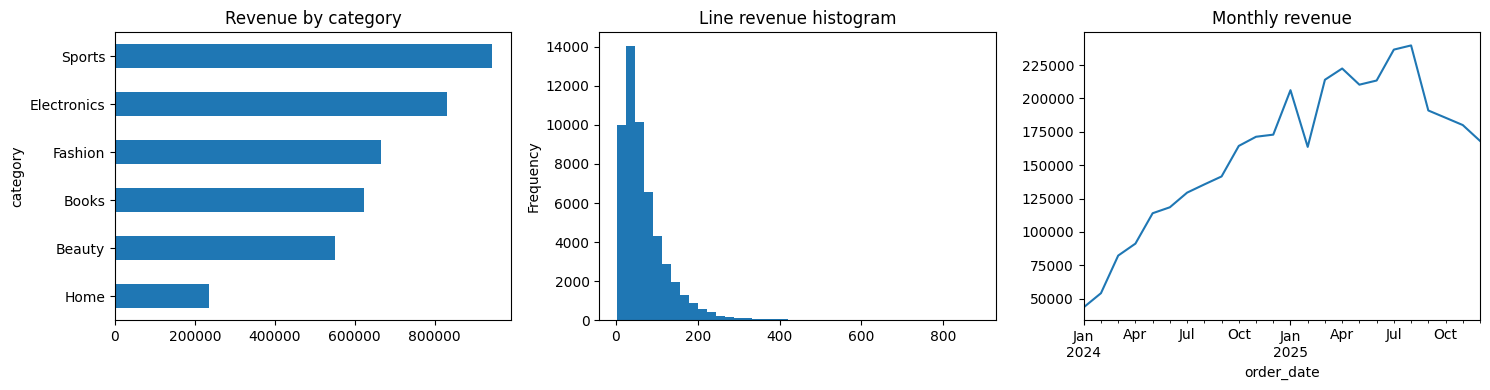

saved eda_basics.png


In [ ]:
h("14. Basic plots")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
m.groupby("category").revenue.sum().sort_values().plot.barh(ax=ax[0], title="Revenue by category")
m.revenue.plot.hist(bins=40, ax=ax[1], title="Line revenue histogram")
m.set_index("order_date").revenue.resample("MS").sum().plot(ax=ax[2], title="Monthly revenue")
fig.tight_layout(); fig.savefig(FIG / "eda_basics.png", dpi=110); plt.show(); print("saved eda_basics.png")

### 15. Save results

In [ ]:
h("15. Save results")
out = BASE / "data" / "eda_basics_summary.csv"
m.groupby("category").revenue.agg(["sum", "mean"]).round(2).to_csv(out); print("wrote", out.name)


======== 15. Save results ========
wrote eda_basics_summary.csv


---
# Part 4: EDA - Intermediate

In [ ]:
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
P = BASE / "data" / "processed"; FIG = BASE / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 170, "display.max_columns", 25); sns.set_theme(style="whitegrid")
def h(t): print(f"\n{'='*8} {t} {'='*8}")

tx = pd.read_csv(P / "transactions_clean.csv", parse_dates=["order_date"])
cu = pd.read_csv(P / "customers_clean.csv", parse_dates=["signup_date"]); pr = pd.read_csv(P / "products_clean.csv")
df = tx.merge(pr[["product_id", "category"]], on="product_id").merge(cu[["customer_id", "acquisition_channel", "age", "gender", "signup_date"]], on="customer_id")

### 1. Data-quality report function

In [ ]:
h("1. Data-quality report function")
def quality_report(d):
    r = pd.DataFrame({"dtype": d.dtypes.astype(str), "nulls": d.isna().sum(), "null_%": (d.isna().mean() * 100).round(2),
                      "unique": d.nunique(), "sample": d.iloc[0]})
    r["constant"] = r["unique"] <= 1; return r
print(quality_report(df))
assert df.duplicated().sum() == 0 and df.line_revenue.gt(0).all()


======== 1. Data-quality report function ========
                              dtype  nulls  null_%  unique               sample  constant
order_id                      int64      0     0.0   22121               113577     False
customer_id                   int64      0     0.0    3996                 2446     False
product_id                    int64      0     0.0      60                   17     False
order_date           datetime64[ns]      0     0.0     730  2025-09-30 00:00:00     False
quantity                      int64      0     0.0       3                    3     False
unit_price                  float64      0     0.0    9127                 62.1     False
discount                    float64      0     0.0       3                  0.1     False
country                      object      0     0.0       6               Canada     False
order_channel                object      0     0.0       3                  App     False
line_revenue                float64      0     0.

### 2. Missing-data strategies (simulate then compare)

In [ ]:
h("2. Missing-data strategies (simulate then compare)")
rng = np.random.default_rng(0); s = df.age.astype(float).copy(); true = s.copy()
mask = rng.random(len(s)) < 0.1; s[mask] = np.nan
cands = {"mean": s.fillna(s.mean()), "median": s.fillna(s.median()),
         "group-median(country)": s.fillna(df.groupby("country").age.transform("median")), "ffill": s.ffill()}
print({k: round(float(np.abs(v[mask] - true[mask]).mean()), 2) for k, v in cands.items()}, "<- MAE vs truth")
df["age_missing_flag"] = s.isna().astype(int)        # missing indicator feature


======== 2. Missing-data strategies (simulate then compare) ========
{'mean': 12.7, 'median': 12.71, 'group-median(country)': 12.69, 'ffill': 16.91} <- MAE vs truth


### 3. Outlier detection

In [ ]:
h("3. Outlier detection")
x = df.groupby("order_id").line_revenue.sum()
q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1; lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
z = (x - x.mean()) / x.std(); med = x.median(); mad = (x - med).abs().median(); mz = 0.6745 * (x - med) / mad
print(f"IQR fences [{lo:.0f}, {hi:.0f}] -> {(x > hi).sum()} | Z>3 -> {(z.abs() > 3).sum()} | MAD>3.5 -> {(mz.abs() > 3.5).sum()}")
xw = x.clip(x.quantile(.01), x.quantile(.99)); print("winsorised max:", round(xw.max(), 1), "| log1p skew:", round(np.log1p(x).skew(), 2), "vs", round(x.skew(), 2))


======== 3. Outlier detection ========
IQR fences [-164, 474] -> 823 | Z>3 -> 357 | MAD>3.5 -> 558
winsorised max: 647.5 | log1p skew: -0.5 vs 1.74


### 4. Univariate

In [ ]:
h("4. Univariate")
num = df[["quantity", "unit_price", "discount", "line_revenue", "age"]]
print(num.agg(["mean", "median", "std", "skew", "kurt", "min", "max"]).round(2).T)
print(df.order_channel.value_counts(normalize=True).round(3).to_dict(), df.category.nunique(), df.gender.value_counts().to_dict())


======== 4. Univariate ========
               mean  median    std  skew   kurt    min     max
quantity       2.00    2.00   0.82 -0.00  -1.50   1.00    3.00
unit_price    36.93   30.31  26.34  2.64  12.67   2.83  362.82
discount       0.04    0.05   0.04  0.48  -1.39   0.00    0.10
line_revenue  71.15   53.23  61.97  2.83  14.45   3.71  883.83
age           43.30   43.00  14.84  0.02  -1.18  18.00   69.00
{'Web': 0.504, 'App': 0.349, 'Store': 0.147} 6 {'F': 26307, 'M': 25753, 'Other': 2046}


### 5. Bivariate

In [ ]:
h("5. Bivariate")
print(df.groupby("acquisition_channel").line_revenue.agg(["mean", "median", "std"]).round(1))
print(pd.crosstab(df.order_channel, df.country, normalize="index").round(2))
print(df.groupby(pd.cut(df.age, [17, 25, 35, 45, 55, 70]), observed=True).line_revenue.mean().round(1).to_dict())


======== 5. Bivariate ========
                     mean  median   std
acquisition_channel                    
Email                69.6    51.9  59.4
Organic              72.7    54.2  63.7
Paid Search          70.0    52.5  61.3
Referral             71.2    53.9  61.0
Social               71.4    53.4  62.5
country        Australia  Canada  Germany  India    Uk   Usa
order_channel                                               
App                  0.1     0.1     0.09   0.33  0.14  0.23
Store                0.1     0.1     0.09   0.32  0.14  0.24
Web                  0.1     0.1     0.09   0.32  0.14  0.24
{Interval(17, 25, closed='right'): 69.5, Interval(25, 35, closed='right'): 72.2, Interval(35, 45, closed='right'): 69.7, Interval(45, 55, closed='right'): 71.8, Interval(55, 70, closed='right'): 72.0}


### 6. Correlation (Pearson vs Spearman)

In [ ]:
h("6. Correlation (Pearson vs Spearman)")
print(num.corr().round(2)); print(num.corr(method="spearman").round(2).loc["line_revenue"].to_dict())


======== 6. Correlation (Pearson vs Spearman) ========
              quantity  unit_price  discount  line_revenue   age
quantity          1.00        0.00     -0.00          0.47  0.00
unit_price        0.00        1.00      0.00          0.82  0.01
discount         -0.00        0.00      1.00         -0.05  0.00
line_revenue      0.47        0.82     -0.05          1.00  0.01
age               0.00        0.01      0.00          0.01  1.00
{'quantity': 0.58, 'unit_price': 0.79, 'discount': -0.05, 'line_revenue': 1.0, 'age': 0.01}


### 7. Group stats: transform, rank, cumulative

In [ ]:
h("7. Group stats: transform, rank, cumulative")
orders = df.groupby(["order_id", "customer_id", "order_date"], as_index=False).line_revenue.sum().rename(columns={"line_revenue": "order_value"})
orders = orders.sort_values(["customer_id", "order_date"])
g = orders.groupby("customer_id")
orders["order_seq"] = g.cumcount() + 1; orders["cum_spend"] = g.order_value.cumsum()
orders["days_since_prev"] = g.order_date.diff().dt.days; orders["pct_of_cust_total"] = orders.order_value / g.order_value.transform("sum")
orders["rank_in_cust"] = g.order_value.rank(ascending=False, method="dense")
print(orders.head(6).round({"order_value": 2, "cum_spend": 2, "pct_of_cust_total": 3})); print("median repeat gap (days):", orders.days_since_prev.median())


======== 7. Group stats: transform, rank, cumulative ========
   order_id  customer_id order_date  order_value  order_seq  cum_spend  days_since_prev  pct_of_cust_total  rank_in_cust
0    100001            1 2024-10-24       176.08          1     176.08              NaN              0.347           2.0
1    100002            1 2025-03-17       222.86          2     398.94            144.0              0.440           1.0
2    100003            1 2025-10-23       107.82          3     506.76            220.0              0.213           3.0
3    100004            2 2024-09-24        29.74          1      29.74              NaN              1.000           1.0
4    100005            3 2024-04-09        88.07          1      88.07              NaN              0.158           4.0
5    100006            3 2024-11-27       137.66          2     225.73            232.0              0.247           1.0
median repeat gap (days): 23.0


### 8. Time series: resample, rolling, growth

In [ ]:
h("8. Time series: resample, rolling, growth")
ts = orders.set_index("order_date").order_value.resample("MS").agg(["sum", "count"]); ts["mom_%"] = ts["sum"].pct_change() * 100
ts["ma3"] = ts["sum"].rolling(3).mean(); ts["yoy_%"] = ts["sum"].pct_change(12) * 100
print(ts.round(1).tail(6)); print("weekday revenue share:", df.groupby(df.order_date.dt.day_name()).line_revenue.sum().div(df.line_revenue.sum()).round(3).to_dict())


======== 8. Time series: resample, rolling, growth ========
                 sum  count  mom_%       ma3  yoy_%
order_date                                         
2025-07-01  236598.9   1373   10.9  220117.1   82.8
2025-08-01  239731.4   1376    1.3  229921.0   76.8
2025-09-01  190977.2   1054  -20.3  222435.8   34.9
2025-10-01  185546.3   1070   -2.8  205418.3   12.8
2025-11-01  180060.9    981   -3.0  185528.1    5.1
2025-12-01  168191.7    952   -6.6  177933.0   -2.7
weekday revenue share: {'Friday': 0.14, 'Monday': 0.142, 'Saturday': 0.146, 'Sunday': 0.141, 'Thursday': 0.144, 'Tuesday': 0.143, 'Wednesday': 0.143}


### 9. Feature engineering

In [ ]:
h("9. Feature engineering")
snap = df.order_date.max() + pd.Timedelta(days=1)
rfm = orders.groupby("customer_id").agg(recency=("order_date", lambda s: (snap - s.max()).days), frequency=("order_id", "nunique"),
                                        monetary=("order_value", "sum"), first=("order_date", "min"), aov=("order_value", "mean"), gap=("days_since_prev", "mean"))
rfm["tenure"] = (snap - rfm["first"]).dt.days; rfm["orders_per_month"] = rfm.frequency / (rfm.tenure / 30).clip(lower=1)
rfm["is_repeat"] = (rfm.frequency > 1).astype(int); rfm["log_monetary"] = np.log1p(rfm.monetary)
for c, asc in [("recency", False), ("frequency", True), ("monetary", True)]:
    rfm[c[0] + "_score"] = pd.qcut(rfm[c].rank(method="first", ascending=asc), 5, labels=False) + 1
rfm["RFM"] = rfm.r_score.astype(str) + rfm.f_score.astype(str) + rfm.m_score.astype(str)
print(rfm.head(3).round({"aov": 2, "gap": 1, "orders_per_month": 2, "log_monetary": 2, "monetary": 2})); print("repeat rate:", rfm.is_repeat.mean().round(3))
df["month_sin"] = np.sin(2 * np.pi * df.order_date.dt.month / 12); df["is_weekend"] = df.order_date.dt.dayofweek >= 5   # cyclical + flag
print(pd.get_dummies(df[["order_channel"]].head(3)).astype(int).to_dict("list"))


======== 9. Feature engineering ========
             recency  frequency  monetary      first     aov    gap  tenure  orders_per_month  is_repeat  log_monetary  r_score  f_score  m_score  RFM
customer_id                                                                                                                                           
1                 69          3    506.76 2024-10-24  168.92  182.0     433              0.21          1          6.23        4        2        3  423
2                463          1     29.74 2024-09-24   29.74    NaN     463              0.06          0          3.43        1        1        1  111
3                218          7    557.99 2024-04-09   79.71   68.8     631              0.33          1          6.33        3        4        3  343
repeat rate: 0.774
{'order_channel_App': [1, 0, 1], 'order_channel_Web': [0, 1, 0]}


### 10. Cohort analysis

In [ ]:
h("10. Cohort analysis")
orders["cohort"] = orders.groupby("customer_id").order_date.transform("min").dt.to_period("M")
orders["idx"] = (orders.order_date.dt.to_period("M") - orders.cohort).apply(lambda p: p.n)
coh = orders.pivot_table(index="cohort", columns="idx", values="customer_id", aggfunc="nunique")
ret = coh.div(coh[0], axis=0); print(ret.iloc[:5, :7].round(2))


======== 10. Cohort analysis ========
idx        0     1     2     3     4     5     6
cohort                                          
2024-01  1.0  0.36  0.38  0.31  0.28  0.23  0.25
2024-02  1.0  0.34  0.26  0.24  0.27  0.31  0.22
2024-03  1.0  0.34  0.32  0.37  0.22  0.25  0.22
2024-04  1.0  0.39  0.29  0.29  0.25  0.24  0.27
2024-05  1.0  0.31  0.30  0.29  0.26  0.24  0.25


### 11. Seaborn gallery


======== 11. Seaborn gallery ========


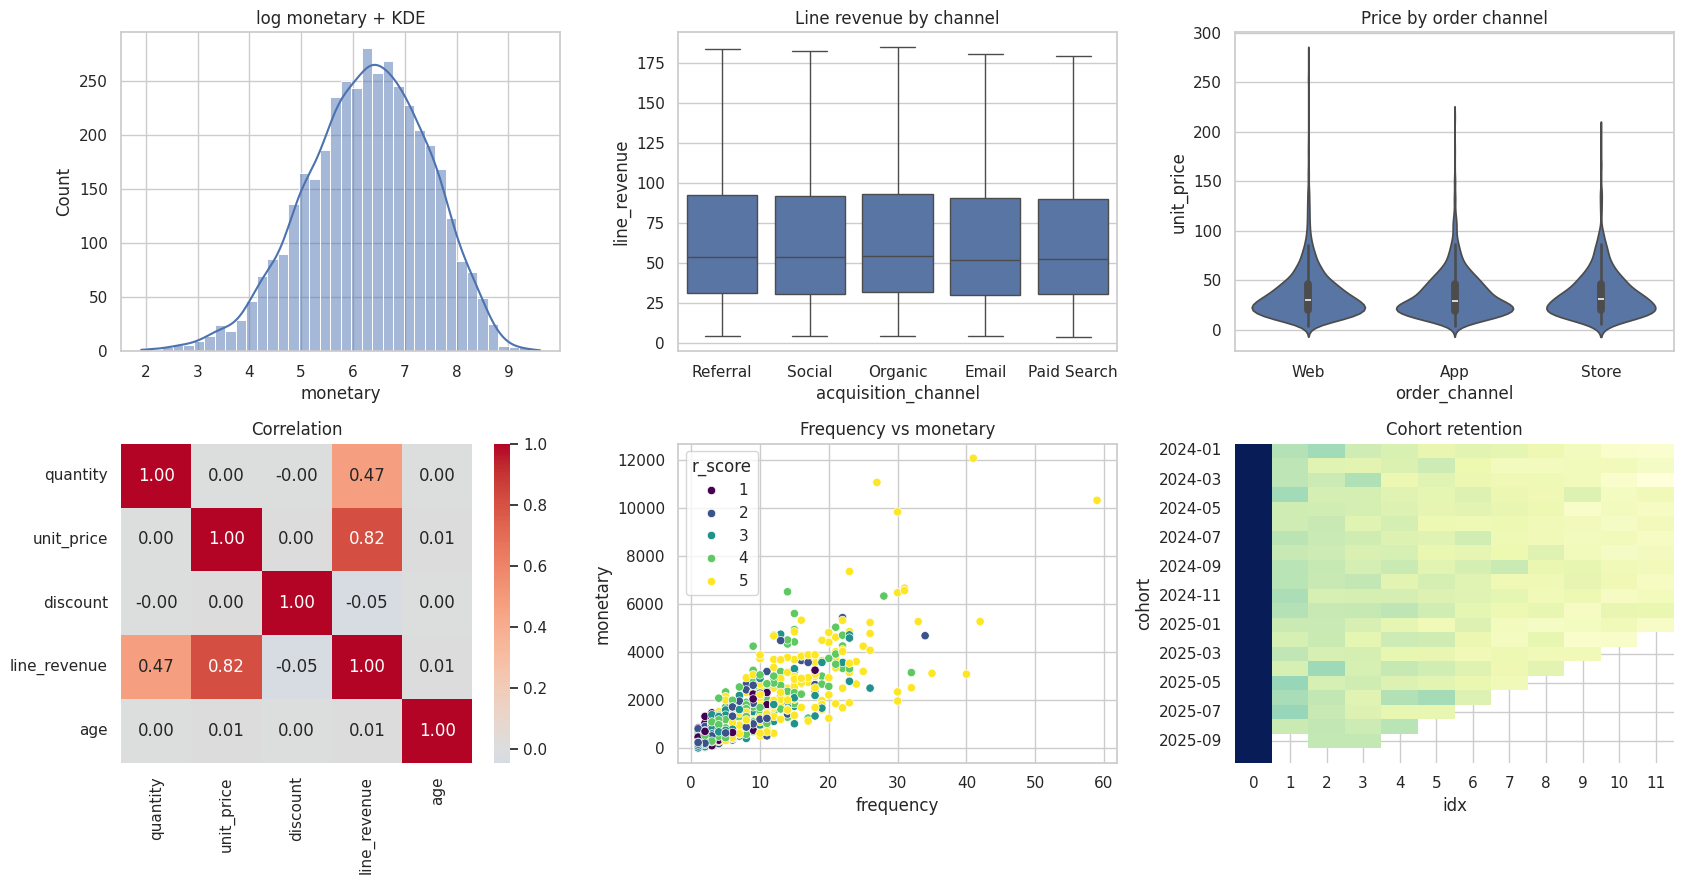

saved eda_intermediate.png


In [ ]:
h("11. Seaborn gallery")
fig, ax = plt.subplots(2, 3, figsize=(17, 9))
sns.histplot(np.log1p(rfm.monetary), kde=True, ax=ax[0, 0]).set(title="log monetary + KDE")
sns.boxplot(data=df, x="acquisition_channel", y="line_revenue", ax=ax[0, 1], showfliers=False).set(title="Line revenue by channel")
sns.violinplot(data=df.sample(5000, random_state=1), x="order_channel", y="unit_price", ax=ax[0, 2]).set(title="Price by order channel")
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1, 0]).set(title="Correlation")
sns.scatterplot(data=rfm.sample(1500, random_state=1), x="frequency", y="monetary", hue="r_score", palette="viridis", ax=ax[1, 1]).set(title="Frequency vs monetary")
sns.heatmap(ret.iloc[:, :12], cmap="YlGnBu", ax=ax[1, 2], cbar=False).set(title="Cohort retention")
fig.tight_layout(); fig.savefig(FIG / "eda_intermediate.png", dpi=110); plt.show(); print("saved eda_intermediate.png")

### 12. Memory / dtype optimisation

In [ ]:
h("12. Memory / dtype optimisation")
before = df.memory_usage(deep=True).sum() / 1e6
opt = df.copy()
for c in opt.select_dtypes(include=["object", "string"]): opt[c] = opt[c].astype("category")
for c in opt.select_dtypes("int64"): opt[c] = pd.to_numeric(opt[c], downcast="integer")
print(f"{before:.1f} MB -> {opt.memory_usage(deep=True).sum()/1e6:.1f} MB")
rfm.reset_index().to_csv(P / "eda_rfm_features.csv", index=False)


======== 12. Memory / dtype optimisation ========
19.8 MB -> 3.5 MB


---
# Part 5: EDA - Advanced

In [ ]:
import json, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest, RandomForestRegressor
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LinearRegression
warnings.filterwarnings("ignore")
P = BASE / "data" / "processed"; FIG = BASE / "reports" / "figures"
def h(t): print(f"\n{'='*8} {t} {'='*8}")
rng = np.random.default_rng(42)

rfm = pd.read_csv(P / "eda_rfm_features.csv"); cu = pd.read_csv(P / "customers_clean.csv")
tx = pd.read_csv(P / "transactions_clean.csv", parse_dates=["order_date"])
d = rfm.merge(cu[["customer_id", "acquisition_channel", "country", "age"]], on="customer_id")

### 1. Distribution shape & normality


======== 1. Distribution shape & normality ========
skew=3.08 kurt=16.27
Shapiro raw  p=2.78e-52 | log p=8.50e-07
D'Agostino log: 0.0 | KS vs lognorm: 0.025
Box-Cox lambda: 0.102 skew after: -0.01


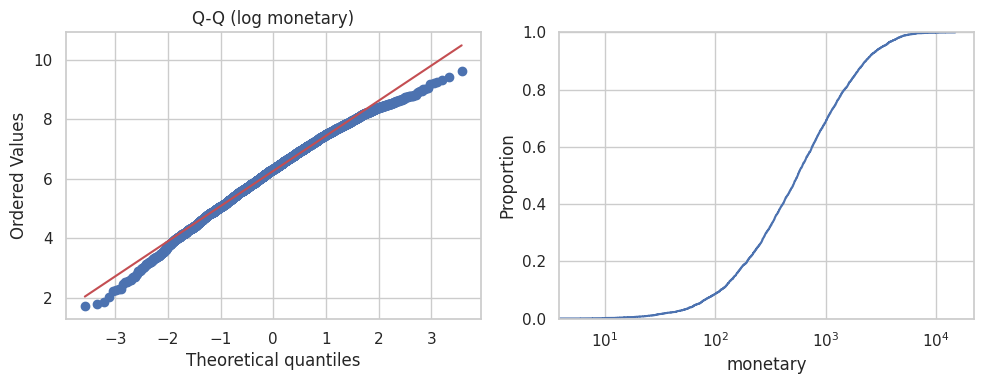

In [ ]:
h("1. Distribution shape & normality")
m = d.monetary
print(f"skew={m.skew():.2f} kurt={m.kurt():.2f}")
samp = m.sample(2000, random_state=1)
print("Shapiro raw  p=%.2e | log p=%.2e" % (stats.shapiro(samp).pvalue, stats.shapiro(np.log(samp)).pvalue))
print("D'Agostino log:", round(stats.normaltest(np.log(m)).pvalue, 4), "| KS vs lognorm:", round(stats.kstest(m, "lognorm", stats.lognorm.fit(m, floc=0)).statistic, 3))
bc, lam = stats.boxcox(m); print("Box-Cox lambda:", round(lam, 3), "skew after:", round(pd.Series(bc).skew(), 3))
fig, ax = plt.subplots(1, 2, figsize=(10, 4)); stats.probplot(np.log(m), plot=ax[0]); ax[0].set_title("Q-Q (log monetary)")
sns.ecdfplot(m, ax=ax[1]); ax[1].set_xscale("log"); fig.tight_layout(); fig.savefig(FIG / "eda_adv_qq.png", dpi=100); plt.show()

### 2. Hypothesis tests

In [ ]:
h("2. Hypothesis tests")
a = d[d.acquisition_channel == "Organic"].monetary; b = d[d.acquisition_channel == "Paid Search"].monetary
print("Welch t-test  :", stats.ttest_ind(a, b, equal_var=False)); print("Mann-Whitney  :", stats.mannwhitneyu(a, b).pvalue.round(4))
groups = [g.monetary.values for _, g in d.groupby("acquisition_channel")]
print("ANOVA p=%.4f | Kruskal p=%.4f | Levene p=%.4f" % (stats.f_oneway(*groups).pvalue, stats.kruskal(*groups).pvalue, stats.levene(*groups).pvalue))
ct = pd.crosstab(d.country, d.is_repeat); chi2, p, dof, _ = stats.chi2_contingency(ct)
print(f"Chi-square repeat~country: chi2={chi2:.2f} dof={dof} p={p:.4f}")
r, p = stats.spearmanr(d.frequency, d.monetary); print(f"Spearman freq~monetary r={r:.3f} p={p:.1e}")
print("Proportion z-like (repeat Organic vs Social):", stats.fisher_exact(pd.crosstab(d.acquisition_channel.isin(["Organic"]), d.is_repeat))[1].round(4))


======== 2. Hypothesis tests ========
Welch t-test  : TtestResult(statistic=np.float64(-0.007487780754423677), pvalue=np.float64(0.9940263763307902), df=np.float64(2118.022520030504))
Mann-Whitney  : 0.3579
ANOVA p=0.5451 | Kruskal p=0.4542 | Levene p=0.4022
Chi-square repeat~country: chi2=5.67 dof=5 p=0.3396
Spearman freq~monetary r=0.890 p=0.0e+00
Proportion z-like (repeat Organic vs Social): 0.4557


### 3. Effect size & multiple-testing correction

In [ ]:
h("3. Effect size & multiple-testing correction")
def cohens_d(x, y): s = np.sqrt(((len(x)-1)*x.var() + (len(y)-1)*y.var()) / (len(x)+len(y)-2)); return (x.mean() - y.mean()) / s
print("Cohen's d (Organic vs Paid):", round(cohens_d(a, b), 3))
chs = sorted(d.acquisition_channel.unique()); pv = []; pairs = []
for i in range(len(chs)):
    for j in range(i + 1, len(chs)):
        pairs.append((chs[i], chs[j])); pv.append(stats.mannwhitneyu(d[d.acquisition_channel == chs[i]].monetary, d[d.acquisition_channel == chs[j]].monetary).pvalue)
pv = np.array(pv); order = pv.argsort(); m_ = len(pv); bh = np.empty(m_); run = 1
for rank, idx in reversed(list(enumerate(order, 1))): run = min(run, pv[idx] * m_ / rank); bh[idx] = run
print("pairs significant (Bonferroni):", int((pv * m_ < .05).sum()), "| (Benjamini-Hochberg):", int((bh < .05).sum()), "of", m_)


======== 3. Effect size & multiple-testing correction ========
Cohen's d (Organic vs Paid): -0.0
pairs significant (Bonferroni): 0 | (Benjamini-Hochberg): 0 of 10


### 4. Bootstrap confidence intervals

In [ ]:
h("4. Bootstrap confidence intervals")
def boot(x, f=np.mean, n=2000): return np.percentile([f(rng.choice(x, len(x))) for _ in range(n)], [2.5, 97.5])
print("mean spend 95% CI:", boot(m.values).round(1), "| median:", boot(m.values, np.median).round(1), "| t-interval:", np.round(stats.t.interval(.95, len(m)-1, m.mean(), stats.sem(m)), 1))


======== 4. Bootstrap confidence intervals ========
mean spend 95% CI: [ 929.  1000.6] | median: [536.5 582.2] | t-interval: [927.4 999.5]


### 5. Multicollinearity - VIF (computed from R^2)

In [ ]:
h("5. Multicollinearity - VIF (computed from R^2)")
X = d[["recency", "frequency", "monetary", "aov", "tenure", "orders_per_month", "gap"]].fillna(0)
vif = {c: 1 / (1 - LinearRegression().fit(X.drop(columns=c), X[c]).score(X.drop(columns=c), X[c])) for c in X}
print({k: round(v, 1) for k, v in vif.items()}, "<- >10 = problematic")


======== 5. Multicollinearity - VIF (computed from R^2) ========
{'recency': 5.3, 'frequency': 13.1, 'monetary': 6.5, 'aov': 1.6, 'tenure': 5.4, 'orders_per_month': 5.9, 'gap': 1.9} <- >10 = problematic


### 6. PCA

In [ ]:
h("6. PCA")
Z = StandardScaler().fit_transform(X); pca = PCA().fit(Z)
print("explained var:", pca.explained_variance_ratio_.round(3), "| comps for 90%:", int(np.argmax(pca.explained_variance_ratio_.cumsum() >= .9)) + 1)
print(pd.DataFrame(pca.components_[:2], columns=X.columns).round(2))


======== 6. PCA ========
explained var: [0.427 0.215 0.161 0.148 0.026 0.016 0.006] | comps for 90%: 4
   recency  frequency  monetary   aov  tenure  orders_per_month   gap
0    -0.41       0.52      0.51  0.09   -0.09              0.53 -0.02
1     0.49       0.26      0.31  0.17    0.73             -0.08 -0.15


### 7. Clustering (KMeans + silhouette)

In [ ]:
h("7. Clustering (KMeans + silhouette)")
Zl = StandardScaler().fit_transform(np.log1p(d[["recency", "frequency", "monetary"]]))
res = {k: round(silhouette_score(Zl, KMeans(k, n_init=5, random_state=1).fit_predict(Zl), sample_size=2000, random_state=1), 3) for k in range(2, 7)}
print("silhouette by k:", res); k = max(res, key=res.get); d["cluster"] = KMeans(k, n_init=10, random_state=1).fit_predict(Zl)
print(d.groupby("cluster").agg(n=("customer_id", "count"), recency=("recency", "mean"), freq=("frequency", "mean"), money=("monetary", "mean")).round(1))


======== 7. Clustering (KMeans + silhouette) ========
silhouette by k: {2: np.float64(0.449), 3: np.float64(0.367), 4: np.float64(0.38), 5: np.float64(0.336), 6: np.float64(0.315)}
            n  recency  freq   money
cluster                             
0        1713    103.6  10.0  1787.8
1        2283    356.7   2.2   344.8


### 8. Anomaly detection

In [ ]:
h("8. Anomaly detection")
iso = IsolationForest(contamination=.01, random_state=1).fit(Zl); d["anom"] = iso.predict(Zl) == -1
print("anomalies:", d.anom.sum(), "\n", d[d.anom].nlargest(3, "monetary")[["customer_id", "frequency", "monetary", "recency"]])


======== 8. Anomaly detection ========
anomalies: 40 
       customer_id  frequency  monetary  recency
2043         2045         41  14935.88        2
3866         3871         41  12079.91       30
1781         1783         27  11074.58       12


### 9. Time series: decomposition & autocorrelation (no statsmodels needed)

In [ ]:
h("9. Time series: decomposition & autocorrelation (no statsmodels needed)")
ts = tx.set_index("order_date").line_revenue.resample("MS").sum(); n = len(ts)
trend = ts.rolling(3, center=True).mean(); resid = ts - trend
print("trend slope/month: %.0f" % np.polyfit(range(n), ts.values, 1)[0], "| ACF lag1/lag2:", round(ts.autocorr(1), 2), round(ts.autocorr(2), 2))
print("residual std:", round(resid.std(), 0), "| last-3 trend:", trend.dropna().tail(3).round(0).tolist())
try:
    from statsmodels.tsa.seasonal import seasonal_decompose; print(seasonal_decompose(ts, period=12).seasonal.head(2))
except ImportError: print("statsmodels not installed -> manual decomposition used")


======== 9. Time series: decomposition & autocorrelation (no statsmodels needed) ========
trend slope/month: 6529 | ACF lag1/lag2: 0.92 0.88
residual std: 11503.0 | last-3 trend: [205418.0, 185528.0, 177933.0]
order_date
2024-01-01    18124.968472
2024-02-01   -33175.940278
Freq: MS, Name: seasonal, dtype: float64


### 10. Pareto / concentration

In [ ]:
h("10. Pareto / concentration")
s = np.sort(m.values); cum = np.cumsum(s) / s.sum(); n = len(s); gini = 1 - 2 * np.trapz(cum, dx=1/n) if hasattr(np, "trapz") else 1 - 2 * np.trapezoid(cum, dx=1/n)
print(f"Gini={gini:.3f} | top 10% share={s[-n//10:].sum()/s.sum():.1%} | top 20% share={s[-n//5:].sum()/s.sum():.1%} | bottom 50% share={s[:n//2].sum()/s.sum():.1%}")


======== 10. Pareto / concentration ========
Gini=0.546 | top 10% share=38.5% | top 20% share=57.8% | bottom 50% share=13.4%


### 11. Feature importance & mutual information

In [ ]:
h("11. Feature importance & mutual information")
feat = ["recency", "frequency", "aov", "tenure", "orders_per_month", "gap", "age"]
Xf = d[feat].fillna(0); y = np.log1p(d.monetary)
print("MI:", {f: float(round(v, 2)) for f, v in zip(feat, mutual_info_regression(Xf, y, random_state=1))})
rf = RandomForestRegressor(150, random_state=1, n_jobs=-1).fit(Xf, y); print("RF importance:", {f: float(round(v, 2)) for f, v in zip(feat, rf.feature_importances_)})


======== 11. Feature importance & mutual information ========
MI: {'recency': 0.16, 'frequency': 0.78, 'aov': 2.52, 'tenure': 0.01, 'orders_per_month': 0.46, 'gap': 0.37, 'age': 0.01}
RF importance: {'recency': 0.0, 'frequency': 0.7, 'aov': 0.28, 'tenure': 0.0, 'orders_per_month': 0.0, 'gap': 0.02, 'age': 0.0}


### 12. Leakage-safe split (time-based + fit scaler on train only)

In [ ]:
h("12. Leakage-safe split (time-based + fit scaler on train only)")
cut = pd.Timestamp("2025-06-30"); tr_c = tx[tx.order_date <= cut].customer_id.unique(); te_c = tx[tx.order_date > cut].customer_id.unique()
print(f"train-period customers {len(tr_c):,} | holdout-period customers {len(te_c):,} | overlap {len(set(tr_c) & set(te_c)):,}")
print("RULE: build features only from data <= cutoff; target from data > cutoff; fit transformers on train only")


======== 12. Leakage-safe split (time-based + fit scaler on train only) ========
train-period customers 3,602 | holdout-period customers 1,884 | overlap 1,490
RULE: build features only from data <= cutoff; target from data > cutoff; fit transformers on train only


### 13. OLS with statsmodels (optional)

In [ ]:
h("13. OLS with statsmodels (optional)")
try:
    import statsmodels.api as sm; ols = sm.OLS(y, sm.add_constant(Xf)).fit(); print(ols.summary().tables[1])
except ImportError:
    from sklearn.linear_model import LinearRegression as LR; lr = LR().fit(Xf, y); print("sklearn OLS R2=%.3f coefs=%s" % (lr.score(Xf, y), {f: float(round(c, 4)) for f, c in zip(feat, lr.coef_)}))


======== 13. OLS with statsmodels (optional) ========
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const                4.0885      0.039    105.415      0.000       4.012       4.165
recency             -0.0026   8.27e-05    -31.774      0.000      -0.003      -0.002
frequency            0.0244      0.004      6.549      0.000       0.017       0.032
aov                  0.0054   7.45e-05     71.904      0.000       0.005       0.006
tenure               0.0031   9.76e-05     32.128      0.000       0.003       0.003
orders_per_month     1.0977      0.042     26.442      0.000       1.016       1.179
gap                 -0.0009      0.000     -4.999      0.000      -0.001      -0.001
age                 -0.0003      0.000     -0.675      0.500      -0.001       0.001


### 14. Automated EDA summary -> JSON

In [ ]:
h("14. Automated EDA summary -> JSON")
summary = {"rows": int(len(tx)), "customers": int(d.customer_id.nunique()), "revenue": round(float(tx.line_revenue.sum()), 2),
           "repeat_rate": round(float(d.is_repeat.mean()), 3), "gini": round(float(gini), 3), "clusters": int(k),
           "anomalies": int(d.anom.sum()), "high_vif": [c for c, v in vif.items() if v > 10]}
(P / "eda_summary.json").write_text(json.dumps(summary, indent=2)); print(summary)


======== 14. Automated EDA summary -> JSON ========
{'rows': 54106, 'customers': 3996, 'revenue': 3849772.26, 'repeat_rate': 0.774, 'gini': 0.546, 'clusters': 2, 'anomalies': 40, 'high_vif': ['frequency']}


---
# Part 6: Analytics - CLV prediction model

In [ ]:
import json, warnings
import numpy as np, pandas as pd, matplotlib

import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
warnings.filterwarnings("ignore")


PROC, FIG = BASE / "data" / "processed", BASE / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
CUTOFF, HORIZON_DAYS, SEED = pd.Timestamp("2025-06-30"), 183, 42

tx = pd.read_csv(PROC / "transactions_clean.csv", parse_dates=["order_date"])
cu = pd.read_csv(PROC / "customers_clean.csv", parse_dates=["signup_date"])
pr = pd.read_csv(PROC / "products_clean.csv")
tx = tx.merge(pr[["product_id", "category"]], on="product_id")
CAT = ["country", "acquisition_channel"]

### feature builder

In [ ]:
# ------------------------------------------------------------ feature builder
def build_features(tx, asof):
    h = tx[tx.order_date <= asof]
    o = h.groupby(["order_id", "customer_id", "order_date"], as_index=False).line_revenue.sum()
    g = o.groupby("customer_id")
    f = pd.DataFrame({
        "frequency": g.order_id.nunique(), "monetary": g.line_revenue.sum(), "aov": g.line_revenue.mean(),
        "recency_days": (asof - g.order_date.max()).dt.days,
        "tenure_days": (asof - g.order_date.min()).dt.days})
    o = o.sort_values(["customer_id", "order_date"])
    gap = o.groupby("customer_id").order_date.diff().dt.days
    f["avg_gap_days"] = gap.groupby(o.customer_id).mean().reindex(f.index).fillna(f.tenure_days.clip(lower=1))
    f["recency_ratio"] = f.recency_days / f.avg_gap_days.clip(lower=1)     # "overdue-ness"
    for d in (90, 180):
        r = o[o.order_date > asof - pd.Timedelta(days=d)].groupby("customer_id")
        f[f"orders_last_{d}d"] = r.order_id.nunique().reindex(f.index).fillna(0)
        f[f"rev_last_{d}d"] = r.line_revenue.sum().reindex(f.index).fillna(0)
    f["n_categories"] = h.groupby("customer_id").category.nunique()
    f["avg_discount"] = h.groupby("customer_id").discount.mean()
    f["app_share"] = h.assign(a=h.order_channel.eq("App")).groupby("customer_id").a.mean()
    f = f.reset_index().merge(cu[["customer_id", "age", "country", "acquisition_channel"]], on="customer_id")
    return pd.get_dummies(f, columns=CAT, drop_first=True, dtype=float)

def target(tx, start, days):
    t = tx[(tx.order_date > start) & (tx.order_date <= start + pd.Timedelta(days=days))]
    return t.groupby("customer_id").line_revenue.sum()

### train / evaluate

In [ ]:
# ------------------------------------------------------------ train / evaluate
X = build_features(tx, CUTOFF)
X["y"] = X.customer_id.map(target(tx, CUTOFF, HORIZON_DAYS)).fillna(0)
feats = [c for c in X.columns if c not in ("customer_id", "y")]
tr, te = train_test_split(X, test_size=0.25, random_state=SEED)
print(f"customers={len(X):,} | train={len(tr):,} test={len(te):,} | avg 6m revenue=${X.y.mean():,.0f} "
      f"| active in holdout={(X.y > 0).mean():.1%}")

def metrics(name, y, p):
    m = {"model": name, "MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** .5,
         "R2": r2_score(y, p), "Spearman": spearmanr(y, p)[0]}
    top = np.argsort(-np.asarray(p))[:max(1, len(y) // 10)]
    m["Top10%_capture"] = float(np.asarray(y)[top].sum() / np.sum(y))      # share of true revenue found in top decile
    return m

res = []
base_p = te.monetary / (te.tenure_days.clip(lower=30) / 30) * 6          # naive: historical monthly spend x 6
res.append(metrics("Baseline (hist. run-rate)", te.y, base_p))

try:                                                                     # statsmodels OLS
    import statsmodels.api as sm
    ols = sm.OLS(tr.y, sm.add_constant(tr[feats])).fit()
    p = ols.predict(sm.add_constant(te[feats], has_constant="add")).clip(lower=0)
    res.append(metrics("OLS (statsmodels)", te.y, p))
    pd.DataFrame({"coef": ols.params, "p_value": ols.pvalues}).round(4).to_csv(PROC / "ols_summary.csv")
except ImportError:
    print("statsmodels not installed -> skipping OLS (pip install statsmodels)")

gbr = GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8,
                                loss="huber", random_state=SEED).fit(tr[feats], tr.y)
pg = np.clip(gbr.predict(te[feats]), 0, None)
res.append(metrics("GradientBoosting (sklearn)", te.y, pg))
rep = pd.DataFrame(res).round(3); print("\n", rep.to_string(index=False))
rep.to_csv(PROC / "model_metrics.csv", index=False)

customers=3,602 | train=2,701 test=901 | avg 6m revenue=$271 | active in holdout=41.4%

                      model     MAE    RMSE     R2  Spearman  Top10%_capture
 Baseline (hist. run-rate) 469.503 752.478 -0.952     0.496           0.343
         OLS (statsmodels) 256.812 458.994  0.274     0.601           0.331
GradientBoosting (sklearn) 236.491 462.626  0.262     0.618           0.341


### charts

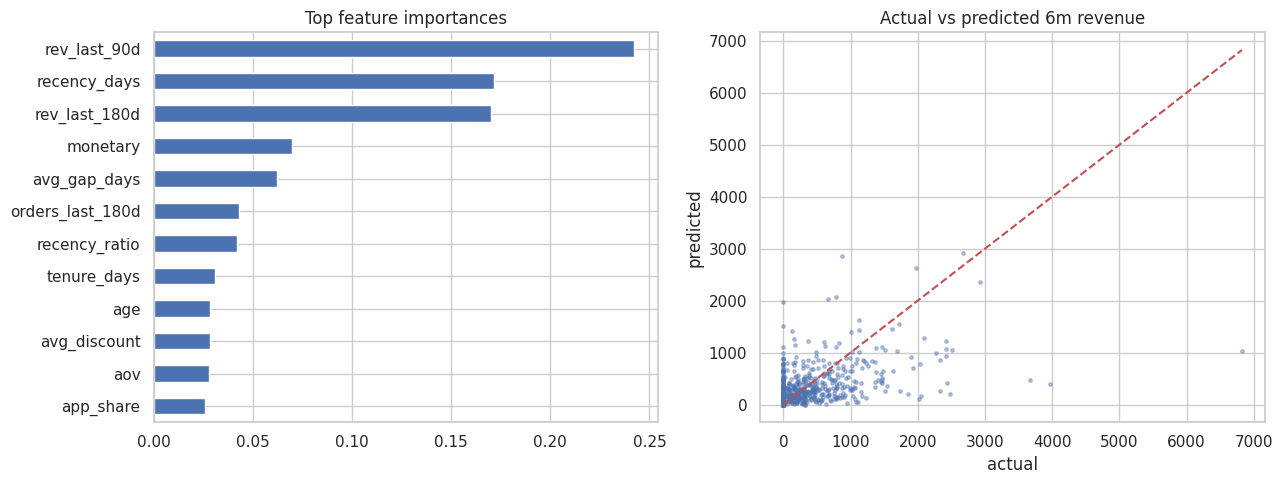

In [ ]:
# ------------------------------------------------------------ charts
imp = pd.Series(gbr.feature_importances_, feats).sort_values().tail(12)
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
imp.plot.barh(ax=axs[0], title="Top feature importances")
axs[1].scatter(te.y, pg, s=6, alpha=.4); lim = max(te.y.max(), pg.max())
axs[1].plot([0, lim], [0, lim], "r--"); axs[1].set(title="Actual vs predicted 6m revenue", xlabel="actual", ylabel="predicted")
fig.tight_layout(); fig.savefig(FIG / "07_model_diagnostics.png", dpi=130); plt.show()

### final scoring (as of last data date)

In [ ]:
# ------------------------------------------------------------ final scoring (as of last data date)
ASOF = tx.order_date.max()
final = build_features(tx, ASOF)
for c in feats:                                   # align dummy columns
    if c not in final: final[c] = 0.0
final["predicted_clv_6m"] = np.clip(gbr.predict(final[feats]), 0, None).round(2)
final["total_clv"] = (final.monetary + final.predicted_clv_6m).round(2)
q = final.predicted_clv_6m.rank(pct=True)
final["clv_segment"] = np.select([q > .9, q > .7, q > .4], ["Platinum", "Gold", "Silver"], "Bronze")

keep = ["customer_id", "recency_days", "frequency", "monetary", "aov", "tenure_days", "predicted_clv_6m", "total_clv", "clv_segment"]
out = final[keep].merge(cu[["customer_id", "country", "acquisition_channel", "age", "gender", "signup_date"]], on="customer_id")
rfm = pd.read_csv(PROC / "rfm.csv")[["customer_id", "rfm_segment"]]
out = out.merge(rfm, on="customer_id", how="left")
out.to_csv(PROC / "clv_predictions.csv", index=False)
seg = out.groupby("clv_segment").agg(customers=("customer_id", "count"), pred_clv=("predicted_clv_6m", "sum"),
                                     avg_clv=("predicted_clv_6m", "mean"), hist_rev=("monetary", "sum")).round(0)
print("\nSegment summary\n", seg.sort_values("avg_clv", ascending=False))
json.dump({"cutoff": str(CUTOFF.date()), "scored_asof": str(ASOF.date()), "n_customers": len(out)},
          open(PROC / "model_run.json", "w"))


Segment summary
              customers  pred_clv  avg_clv   hist_rev
clv_segment                                         
Platinum           400  390933.0    977.0  1251667.0
Gold               799  252070.0    315.0  1001483.0
Silver            1199   82156.0     69.0   723466.0
Bronze            1598   13349.0      8.0   873156.0


### Download results (Colab only)

In [ ]:
if IN_COLAB:
    from google.colab import files
    for f in ['data/processed/clv_predictions.csv', 'data/processed/model_metrics.csv']:
        files.download(str(BASE / f))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>